[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

用 H、受控旋转和 SWAP 构建三比特 QFT。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 量子傅里叶变换

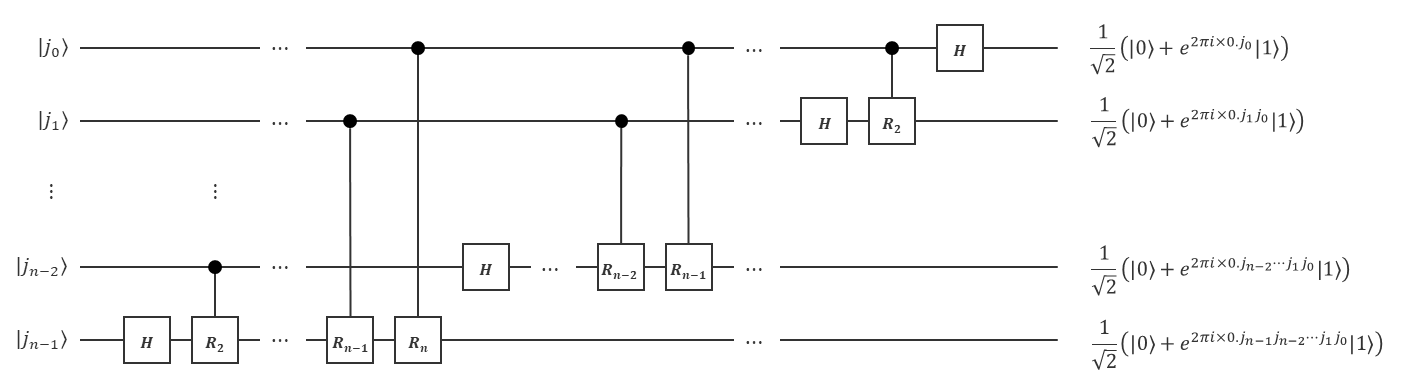

## 例1
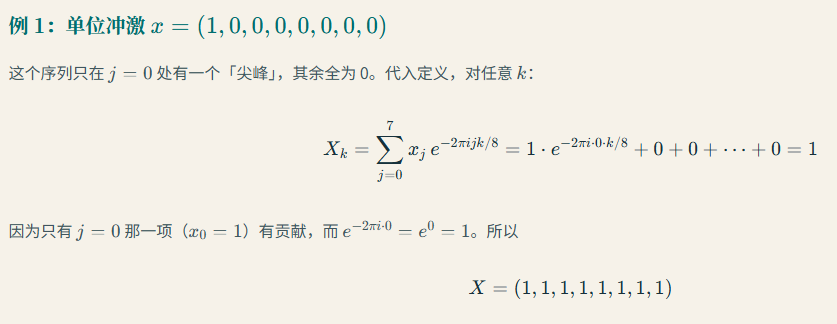

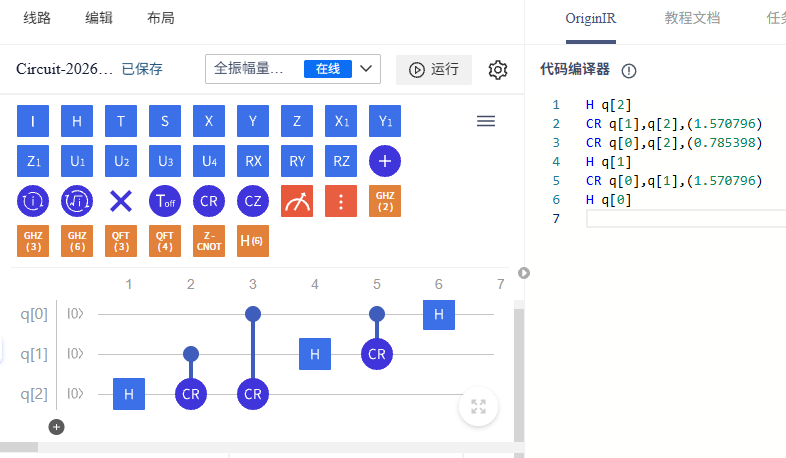

In [1]:
from numpy import pi
from pyqpanda3.core import H, CR, QCircuit, SWAP, draw_qprog
from pyqpanda3.quantum_info import StateVector

In [2]:
qft_q3 = QCircuit(3)
qft_q3 << H(2) << CR(1, 2, pi/2) << CR(0, 2, pi/4)
qft_q3 << H(1) << CR(0, 1, pi/2)
qft_q3 << H(0)

qft_q3 << SWAP(0, 2)

print(draw_qprog(qft_q3, param_show=True))


                                                                 ┌─┐   
q_0:  |0>──── ──────────────── ────────*─────── ────────*─────── ┤H├ X 
                                       │┌─┐     ┌───────┴──────┐ └─┘ │ 
q_1:  |0>──── ────────*─────── ────────┼┤H├──── ┤CP(1.57079633)├ ─── ┼ 
          ┌─┐ ┌───────┴──────┐ ┌───────┴┴─┴───┐ └──────────────┘     │ 
q_2:  |0>─┤H├ ┤CP(1.57079633)├ ┤CP(0.78539816)├ ──────────────── ─── X 
          └─┘ └──────────────┘ └──────────────┘                        
 c :   / ═════════════════════════════════════════════════════════════
                                                                      




In [3]:
init_state = StateVector(3) # |00\rangle
final_state = init_state.evolve(qft_q3)
print(final_state)

[0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j
 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j]


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

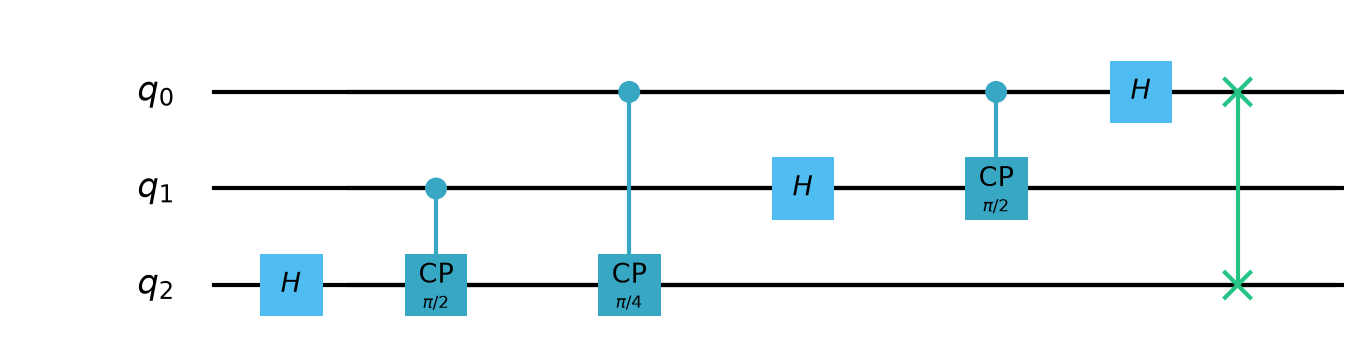

In [4]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day1"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "06_quantum_fourier_transform.png"
qft_q3.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
